pydicom come with its inbuilt image which I will use while learning it.

In [1]:
from pydicom.data import get_testdata_file #A helper that gives the path to a sample DICOM file shipped with pydicom
path = get_testdata_file("CT_small.dcm")
print(path)

C:\Users\riyari\AppData\Local\miniconda3\Lib\site-packages\pydicom\data\test_files\CT_small.dcm


https://github.com/pydicom/pydicom/tree/main/src/pydicom/data/test_files

As evident by its name, dcmread reads and parses a DICOM file into a Dataset object, allowing one to access and manipulate medical imaging data.

In [2]:
from pydicom import dcmread
ds = dcmread(path)

dir() function can be used to list the attributes of an object.

In [4]:
print(dir(ds))

['AccessionNumber', 'AcquisitionDate', 'AcquisitionNumber', 'AcquisitionTime', 'AdditionalPatientHistory', 'BitsAllocated', 'BitsStored', 'Columns', 'ContentDate', 'ContentTime', 'ContrastBolusAgent', 'ContrastBolusRoute', 'ConvolutionKernel', 'DataCollectionDiameter', 'DataSetTrailingPadding', 'DistanceSourceToDetector', 'DistanceSourceToPatient', 'Exposure', 'ExposureTime', 'FilterType', 'FocalSpots', 'FrameOfReferenceUID', 'GantryDetectorTilt', 'HighBit', 'ImageComments', 'ImageOrientationPatient', 'ImagePositionPatient', 'ImageType', 'InstanceCreationDate', 'InstanceCreationTime', 'InstanceCreatorUID', 'InstanceNumber', 'InstitutionName', 'KVP', 'Laterality', 'Manufacturer', 'ManufacturerModelName', 'Modality', 'OtherPatientIDsSequence', 'PatientAge', 'PatientBirthDate', 'PatientID', 'PatientName', 'PatientPosition', 'PatientSex', 'PatientWeight', 'PhotometricInterpretation', 'PixelData', 'PixelPaddingValue', 'PixelRepresentation', 'PixelSpacing', 'PositionReferenceIndicator', 'Rec

In [5]:
ds.Modality #we know the answer because filename is CT_small.dcm

'CT'

In [7]:
#Actual image data is in pixel_array
arr = ds.pixel_array
arr.shape

(128, 128)

In [11]:
#We can also get this information using Rows and Columns
print(ds.Rows, ds.Columns)

128 128


In [20]:
import matplotlib.pyplot as plt

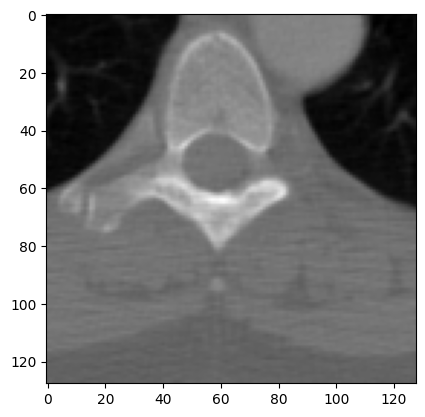

In [21]:
#plt.imshow is used for displaying images especially when each value in the array corresponds to a color.
plt.imshow(arr, cmap="gray")
plt.show()

In [14]:
#DICOM images often store Unsigned integers and needs to be mapped to image. 
print(ds.RescaleSlope, ds.RescaleIntercept)

1 -1024


In [15]:
#For eg., CT images use Hounsfield Units (HU) which can be negative. 
img = arr * ds.RescaleSlope + ds.RescaleIntercept

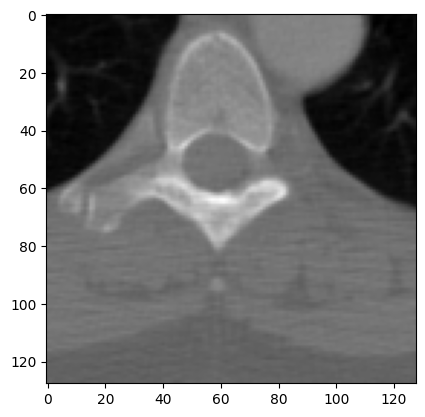

In [22]:
#matplotlib takes the min and max of the array and linearly maps them on grayscale. Therefore, the image looks identical.
plt.imshow(arr, cmap="gray")
plt.show()

Now I want to see how to load a image stored in my computer. I got a sample dicom from https://www.kaggle.com/datasets/abbymorgan/cranial-ct

In [26]:
ds = dcmread("data/Sample.dcm")

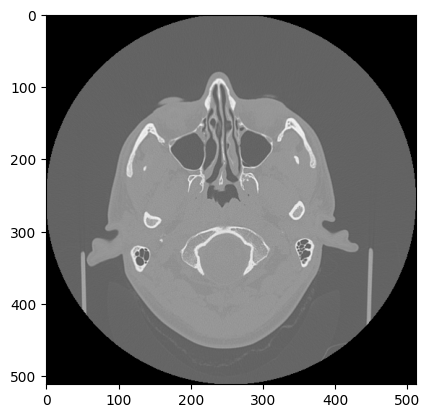

In [27]:
plt.imshow(ds.pixel_array, cmap="gray")
plt.show()